### Data

This cell documents the traffic scene object detection experiment. For the full original methodology, mathematical derivations, and commentary, see the archived notebook in `archive/original_notebooks/`.


In [1]:
from google.colab import drive
drive.mount('/content/drive')

# Note on Dataset, Data. Refer to the archived source for the detailed original comment.
!ls /content/drive/MyDrive/datasets/d2_city_yolo/   # 应该看到 images/ 和 labels/

Mounted at /content/drive
images	labels


### File / Generate

This cell documents the traffic scene object detection experiment. For the full original methodology, mathematical derivations, and commentary, see the archived notebook in `archive/original_notebooks/`.


In [2]:
import yaml
import os

dataset_root = "/content/drive/MyDrive/datasets/d2_city_yolo"  # 实际路径

# Note on Load. Refer to the archived source for the detailed original comment.
classes_path = os.path.join(dataset_root, "labels", "classes.txt")
with open(classes_path, 'r') as f:
    class_names = [line.strip() for line in f.readlines()]

nc = len(class_names)
names = {i: name for i, name in enumerate(class_names)}

data_config = {
    'path': dataset_root,
    'train': 'images/train',
    'val': 'images/val',
    'test': 'images/test',    # 如果有
    'nc': nc,
    'names': names
}

yaml_path = "/content/d2-city.yaml"
with open(yaml_path, 'w') as f:
    yaml.dump(data_config, f, default_flow_style=False)

print("YAML 已生成:")
!cat /content/d2-city.yaml

YAML 已生成:
names:
  0: car
  1: van
  2: bus
  3: truck
  4: person
  5: bicycle
  6: motorcycle
  7: open-tricycle
  8: closed-tricycle
  9: forklift
  10: large-block
  11: small-block
nc: 12
path: /content/drive/MyDrive/datasets/d2_city_yolo
test: images/test
train: images/train
val: images/val


In [3]:
!nvidia-smi

Sat Jul 25 01:27:57 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA A100-SXM4-80GB          Off |   00000000:00:05.0 Off |                    0 |
| N/A   32C    P0             55W /  400W |       0MiB /  81920MiB |      0%      Default |
|                                         |                        |             Disabled |
+-----------------------------------------+-----

In [4]:
!pip install ultralytics -q

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.1/46.1 kB 3.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 51.6 MB/s eta 0:00:00


In [2]:
%%writefile train_exp.py
# train_exp.py

import os
import sys
from ultralytics import YOLO

"""
Part II: YOLO26s - 更换为更大模型并加载 COCO 预训练权重
"""

def experiment_1():
    """实验1: YOLO26s + pretrained (640px)"""
    model = YOLO("yolo26s.pt")          # 加载预训练权重

    model.train(
        data="./d2-city.yaml",
        epochs=150,
        patience=50,
        cache=True,
        imgsz=640,
        batch=16,          # 在显存允许下batch 越大，GPU 利用率越高。对于 26s，若开启 AMP，batch 可尝试 16。
        amp=True,
        rect=True,         # 矩形训练减少填充，提高训练效率
        project=".",            # 保存根目录
        name="exp1"             # 子目录
    )

    metrics = model.val()
    print(f"Exp1 mAP50-95: {metrics.box.map:.4f}")
    print(f"Exp1 mAP50: {metrics.box.map50:.4f}")

"""
Part III: YOLO26n + 预训练权重 + 更高分辨率且数据增强
"""

def experiment_2():
    """实验2: YOLO26n + pretrained + 高分辨率960px + 数据增强"""
    model = YOLO("yolo26n.pt")

    model.train(
        data="./d2-city.yaml",
        epochs=100,
        cache=False,        # Kaggle 关闭缓存
        imgsz=960,
        batch=10,
        rect=True,          # 矩形训练，减少填充
        mosaic=1.0,
        mixup=0.5,
        copy_paste=0.5,
        hsv_h=0.02,
        hsv_s=0.8,
        hsv_v=0.4,
        amp=False,
        project=".",
        name="exp2"
    )
    metrics = model.val()
    print(f"Exp2 mAP50-95: {metrics.box.map:.4f}")
    print(f"Exp2 mAP50: {metrics.box.map50:.4f}")

"""
Part IV: YOLO26m + 预训练权重 + 更高分辨率且数据增强、优化器等
"""

def experiment_3():
    """
    实验3: 激进方案 —— 更大模型 + 高分辨率 + 全面优化
    - 模型: YOLO26m (参数量 ~25M)
    - 分辨率: 960px
    - 优化器: AdamW + 余弦退火
    - 训练轮数: 150, 早停 patience=50
    - 增强: mosaic, mixup, copy_paste, flipud, degrees, scale
    - 标签平滑: 0.1
    - 验证时启用 TTA
    """
    model = YOLO("yolo26m.pt")          # 最大的 YOLO26 模型

    model.train(
        data="./d2-city.yaml",
        cache=True,
        epochs=150,
        patience=50,
        imgsz=800,           # 降低至 800，平衡精度与速度
        batch=8,             # 开启AMP
        rect=True,
        optimizer='AdamW',
        lr0=0.001,
        cos_lr=True,
        label_smoothing=0.1,
        mosaic=0.8,
        mixup=0.4,
        copy_paste=0.5,
        hsv_h=0.02,
        hsv_s=0.8,
        hsv_v=0.4,
        flipud=0.5,
        degrees=5.0,
        save_period=10,
        scale=0.5,
        amp=True,               # 若显存不足可开启 amp=True 节省显存
        project="/content/drive/MyDrive/YOLO_Experiments",  # 父目录
        name="exp3"
    )

    # Note on Validation. Refer to the archived source for the detailed original comment.
    metrics = model.val(augment=True)
    print(f"Exp3 mAP50-95: {metrics.box.map:.4f}")
    print(f"Exp3 mAP50: {metrics.box.map50:.4f}")

"""
Part V: YOLOv11n - 速度与效率对照实验
"""

def experiment_4():
    """实验4: YOLOv11n - 速度与效率对照实验"""
    model = YOLO("yolo11n.pt")  # 或 yolo11s.pt

    model.train(
        data="./d2-city.yaml",
        epochs=150,             # 与实验2/3保持一致
        patience=50,
        cache=True,
        imgsz=800,              # 从标准分辨率开始
        batch=16,
        amp=True,               # 启用混合精度训练
        rect=True,
        project=".",
        name="exp4"
    )

    metrics = model.val()
    print(f"Exp4 (YOLOv11n) mAP50-95: {metrics.box.map:.4f}")
    print(f"Exp4 (YOLOv11n) mAP50: {metrics.box.map50:.4f}")

if __name__ == "__main__":
    # Note on Experiment, Parameters. Refer to the archived source for the detailed original comment.
    # Note on Experiment, Run. Refer to the archived source for the detailed original comment.
    if len(sys.argv) > 1:
        if sys.argv[1] == "2":
            experiment_2()
        elif sys.argv[1] == "3":
            experiment_3()
        elif sys.argv[1] == "4":
            experiment_4()
        else:
            print(f"未知参数: {sys.argv[1]}, 使用默认实验1")
            experiment_1()
    else:
        experiment_1()

Overwriting train_exp.py


In [6]:
# Note on Experiment, Run. Refer to the archived source for the detailed original comment.
!python train_exp.py 3

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
WARNING ⚠️ 'label_smoothing' is deprecated and will be removed in the future.
Ultralytics 8.4.105 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (NVIDIA A100-SXM4-80GB, 81153MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=True, cfg=None, channels_last=False, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.5, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=./d2-city.yaml, degrees=5.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, end2en

### Prediction

This cell documents the traffic scene object detection experiment. For the full original methodology, mathematical derivations, and commentary, see the archived notebook in `archive/original_notebooks/`.



0: 800x800 3 cars, 1 van, 1 bus, 228.8ms
1: 800x800 3 cars, 1 van, 228.8ms
2: 800x800 14 cars, 1 truck, 228.8ms
3: 800x800 3 cars, 1 truck, 228.8ms
4: 800x800 1 car, 1 van, 1 truck, 1 bicycle, 228.8ms
5: 800x800 8 cars, 1 bus, 1 bicycle, 228.8ms
6: 800x800 10 cars, 1 bus, 228.8ms
7: 800x800 9 cars, 1 van, 3 trucks, 1 bicycle, 228.8ms
Speed: 1.2ms preprocess, 228.8ms inference, 0.1ms postprocess per image at shape (1, 3, 800, 800)
预测图像: 11256.jpg


<Figure size 800x600 with 1 Axes>

预测图像: 11104.jpg


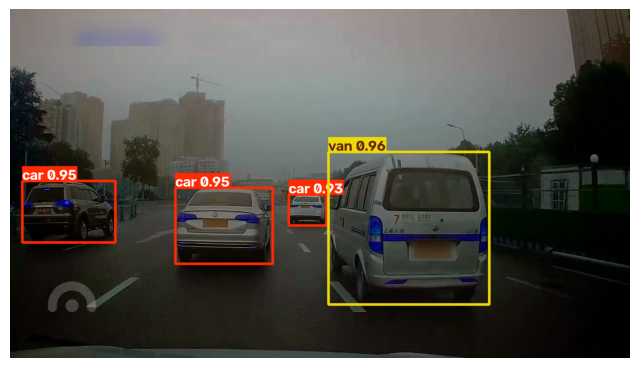

预测图像: 11923.jpg


<Figure size 800x600 with 1 Axes>

预测图像: 11729.jpg


<Figure size 800x600 with 1 Axes>

预测图像: 11766.jpg


<Figure size 800x600 with 1 Axes>

... (2 outputs left out)

预测图像: 11508.jpg


<Figure size 800x600 with 1 Axes>

预测图像: 11285.jpg


<Figure size 800x600 with 1 Axes>

In [11]:
from ultralytics import YOLO
import os
import random
import matplotlib.pyplot as plt

# Note on Model, Training, Load. Refer to the archived source for the detailed original comment.
model = YOLO("/Users/dubby/Desktop/驭风计划/深度学习/作业/实验5-滴滴出行交通场景目标检测/yolo26m_results/weights/best.pt")

# Note on Testing, Image. Refer to the archived source for the detailed original comment.
test_img_dir = "/Users/dubby/Desktop/驭风计划/深度学习/作业/实验5-滴滴出行交通场景目标检测/data/images/test"

# 随机选8个编号 (11000~11999)
indices = random.sample(range(11000, 12000), 8)
test_img_files = [os.path.join(test_img_dir, f"{idx}.jpg") for idx in indices]

# Note on Prediction. Refer to the archived source for the detailed original comment.
results = model(test_img_files)

# Note on Results, Prediction. Refer to the archived source for the detailed original comment.
for i, (file, result) in enumerate(zip(test_img_files, results)):
    print(f"预测图像: {os.path.basename(file)}")
    
    # Note on Image. Refer to the archived source for the detailed original comment.
    annotated_img = result.plot()   # BGR -> RGB 自动转换
    
    # 显示在单元格中
    plt.figure(figsize=(8, 6))
    plt.imshow(annotated_img)
    plt.axis('off')
    plt.show()